# Phân tích Silver → Gold trên MinIO

Chọn kernel Docker Jupyter (Spark **3.5.x**) tại `http://localhost:8888`, **Restart Kernel** một lần sau khi cập nhật notebook, rồi chạy từ trên xuống.
Cell khởi tạo bổ sung Delta Lake 3.3.3 và S3A; lần đầu cần mạng để tải thư viện. CPU và bộ nhớ Spark dùng cấu hình của môi trường.

Notebook đọc **snapshot Delta** của `silver/fact_listen`, giữ sáu nhóm phân tích bên dưới và xuất chín bảng Parquet sang Gold. Không cần đọc lại Bronze hay `listen_versions`.

Cấu hình đọc từ `.env` của dự án; biến môi trường được ưu tiên:
- `MINIO_ENDPOINT`, `MINIO_SECURE`, `MINIO_ACCESS_KEY`, `MINIO_SECRET_KEY` (hoặc `MINIO_ROOT_USER`, `MINIO_ROOT_PASSWORD`). Endpoint phải truy cập được từ kernel; `localhost` trong container là chính container đó.
- `ANALYSIS_MINIO_ENDPOINT`: tùy chọn ghi đè endpoint chỉ cho notebook, ví dụ `http://minio:9000` khi cùng mạng Docker.
- `MINIO_SILVER_BUCKET=silver`, `MINIO_SILVER_PREFIX=`: nơi pipeline đã đồng bộ các bảng Delta.
- `MINIO_GOLD_BUCKET=gold`, `MINIO_GOLD_PREFIX=batch_analysis`: nơi lưu kết quả. Tài khoản cần quyền đọc Silver, ghi Gold; notebook tạo bucket Gold nếu chưa có và tài khoản có quyền tạo.

Mỗi lần xuất tạo thư mục riêng. Chỉ dùng lần xuất có `_manifest.json` với `status=succeeded`; file này được ghi sau khi đọc lại kiểm tra đủ các bảng. Thời gian phân tích và mã lần xuất đều theo UTC.

Tham khảo cấu hình: [Delta Lake / Spark](https://docs.delta.io/releases/), [Delta quick start](https://docs.delta.io/quick-start/).

In [1]:
# Cài thư viện nhỏ vào đúng kernel khi còn thiếu; Spark có sẵn trong image.
import importlib.util

missing = [package for module, package in
           [("dotenv", "python-dotenv"), ("minio", "minio>=7.2,<8")]
           if importlib.util.find_spec(module) is None]
if missing:
    get_ipython().run_line_magic("pip", "install -q " + " ".join(missing))

In [2]:
import os
from pathlib import Path
from urllib.parse import urlsplit
from dotenv import dotenv_values
from minio import Minio
import pyspark
from pyspark import SparkContext
from pyspark.sql import SparkSession, functions as F, Window

env_candidates = [Path("/home/jovyan/work/.env"),
                  *(parent / ".env" for parent in [Path.cwd(), *Path.cwd().parents])]
env_path = next((path for path in env_candidates if path.is_file()), None)
settings = {**(dotenv_values(env_path) if env_path else {}), **os.environ}
access_key = settings.get("MINIO_ACCESS_KEY") or settings.get("MINIO_ROOT_USER")
secret_key = settings.get("MINIO_SECRET_KEY") or settings.get("MINIO_ROOT_PASSWORD")
if not access_key or not access_key.strip() or not secret_key or not secret_key.strip():
    raise ValueError("Cần MINIO_ACCESS_KEY/MINIO_SECRET_KEY hoặc MINIO_ROOT_USER/MINIO_ROOT_PASSWORD trong .env.")

endpoint_raw = settings.get("ANALYSIS_MINIO_ENDPOINT") or settings.get("MINIO_ENDPOINT", "localhost:9000")
endpoint_raw = endpoint_raw.strip().rstrip("/")
secure = str(settings.get("MINIO_SECURE", "false")).lower() in ("true", "1", "yes")
endpoint_url = endpoint_raw if "://" in endpoint_raw else ("https://" if secure else "http://") + endpoint_raw
parsed_endpoint = urlsplit(endpoint_url)
if (parsed_endpoint.scheme not in ("http", "https") or not parsed_endpoint.hostname
        or parsed_endpoint.path or parsed_endpoint.query or parsed_endpoint.fragment
        or parsed_endpoint.username or parsed_endpoint.password):
    raise ValueError("Endpoint MinIO phải có dạng host:port hoặc http(s)://host:port, không chứa đường dẫn hay mật khẩu.")
secure = parsed_endpoint.scheme == "https"
minio_client = Minio(parsed_endpoint.netloc, access_key=access_key, secret_key=secret_key, secure=secure)

silver_bucket = settings.get("MINIO_SILVER_BUCKET") or "silver"
silver_prefix = (settings.get("MINIO_SILVER_PREFIX") or "").strip("/")
gold_bucket = settings.get("MINIO_GOLD_BUCKET") or "gold"
gold_prefix = (settings.get("MINIO_GOLD_PREFIX") or "batch_analysis").strip("/")
SILVER_PATH = "/".join(part for part in [f"s3a://{silver_bucket}", silver_prefix, "fact_listen"] if part)

if tuple(pyspark.__version__.split(".")[:2]) != ("3", "5"):
    raise RuntimeError("Notebook này dùng Spark 3.5.x + Delta 3.3.3. Chọn kernel spark-notebook của dự án.")
packages = "io.delta:delta-spark_2.12:3.3.3,org.apache.hadoop:hadoop-aws:3.3.4,com.amazonaws:aws-java-sdk-bundle:1.12.262"
active_context = SparkContext._active_spark_context
if active_context is not None and "delta-spark" not in active_context.getConf().get("spark.jars.packages", ""):
    raise RuntimeError("Spark đang chạy chưa có Delta. Hãy Restart Kernel rồi chạy lại từ cell đầu.")

s3a_options = {
    "fs.s3a.endpoint": endpoint_url,
    "fs.s3a.access.key": access_key,
    "fs.s3a.secret.key": secret_key,
    "fs.s3a.aws.credentials.provider": "org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider",
    "fs.s3a.path.style.access": "true",
    "fs.s3a.connection.ssl.enabled": str(secure).lower(),
    "fs.s3a.impl": "org.apache.hadoop.fs.s3a.S3AFileSystem",
}
builder = (
    SparkSession.builder.appName("silver-to-gold-analysis")
    .config("spark.shuffle.sort.bypassMergeThreshold", "0")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.jars.packages", packages)
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
)
for key, value in s3a_options.items():
    builder = builder.config("spark.hadoop." + key, value)
spark = builder.getOrCreate()
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()
for key, value in s3a_options.items():
    hadoop_conf.set(key, value)
hadoop_conf.setBoolean("fs.s3a.impl.disable.cache", True)

print("Spark:", spark.version, "| Silver:", SILVER_PATH)
print("Thông tin xác thực được đọc từ môi trường/.env và không hiển thị.")

Spark: 3.5.3 | Silver: s3a://silver/fact_listen
Thông tin xác thực được đọc từ môi trường/.env và không hiển thị.


In [3]:
# Chốt một phiên bản Delta để các bảng Gold cùng đọc một snapshot Silver.
# Chạy lại từ cell này để lấy phiên bản Silver mới nhất.
if "plays" in globals():
    plays.unpersist()
quoted_silver_path = SILVER_PATH.replace("`", "``")
silver_version = int(spark.sql(f"DESCRIBE HISTORY delta.`{quoted_silver_path}` LIMIT 1").first()["version"])
silver = spark.read.format("delta").option("versionAsOf", silver_version).load(SILVER_PATH)
silver.printSchema()
print("Phiên bản Silver:", silver_version)

root
 |-- event_id: string (nullable = false)
 |-- user_id: string (nullable = false)
 |-- listened_at: long (nullable = false)
 |-- listened_date: string (nullable = false)
 |-- dow: integer (nullable = false)
 |-- hour: integer (nullable = false)
 |-- track_id: string (nullable = false)
 |-- track_name: string (nullable = false)
 |-- track_norm: string (nullable = false)
 |-- track_mbid: string (nullable = true)
 |-- artist_id: string (nullable = false)
 |-- artist_name: string (nullable = false)
 |-- artist_norm: string (nullable = false)
 |-- artist_mbid: string (nullable = true)
 |-- album_id: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- album_mbid: string (nullable = true)
 |-- loved: boolean (nullable = false)
 |-- duration_ms: long (nullable = true)
 |-- tags: array (nullable = false)
 |    |-- element: string (containsNull = false)
 |-- tag_source: string (nullable = true)
 |-- crawled_at: long (nullable = false)

Phiên bản Silver: 51


In [4]:
required_columns = {"event_id", "user_id", "listened_at", "track_id", "track_name",
                    "artist_id", "artist_name", "album_id", "tags", "tag_source"}
missing_columns = required_columns - set(silver.columns)
if missing_columns:
    raise ValueError(f"fact_listen thiếu cột: {sorted(missing_columns)}. Kiểm tra đúng bảng Silver.")
print("Số file dữ liệu trong snapshot:", len(silver.inputFiles()))

Số file dữ liệu trong snapshot: 21


## 1. Từ Silver `fact_listen` đến bảng lượt nghe `plays`

Mỗi dòng Silver là một lượt nghe đã được pipeline kiểm tra và khử trùng. Dùng nguyên khóa `user_id` (đặt tên `user` để giữ các phân tích hiện có), `event_id`, `track_id`, `artist_id`, `album_id`. `listened_at` là Unix giây, ánh xạ thành `uts`.

Ngày, giờ, thứ, tháng và tuần được tính lại theo UTC. Notebook dừng nếu Silver rỗng, sai khóa/thời gian hoặc trùng `event_id`, để sửa dữ liệu ở pipeline Silver thay vì âm thầm đổi số liệu. Không dùng các bộ đếm `playcount` tích lũy để đếm lượt nghe.

In [5]:
import csv
import sys
from pyspark import StorageLevel


def show_all(frame):
    """In tiêu đề và từng dòng của bảng theo thứ tự hiện tại."""
    writer = csv.writer(sys.stdout, delimiter="\t", lineterminator="\n")
    writer.writerow(frame.columns)
    formatted = frame.select(*(F.col(c).cast("string") for c in frame.columns))
    for row in formatted.toLocalIterator():
        writer.writerow("NULL" if value is None else value for value in row)


spark.conf.set("spark.sql.session.timeZone", "UTC")
silver_checks = silver.agg(
    F.count("*").alias("rows"), F.countDistinct("event_id").alias("event_ids"),
    F.sum(F.when(
        F.col("event_id").isNull() | (F.length(F.trim("event_id")) == 0)
        | F.col("user_id").isNull() | (F.length(F.trim("user_id")) == 0)
        | F.col("listened_at").isNull() | ~F.col("listened_at").between(0, 253402300799),
        1).otherwise(0)).alias("invalid_rows"),
).first()
n_plays = silver_checks["rows"]
if n_plays == 0:
    raise ValueError("Silver fact_listen rỗng. Chạy và đồng bộ pipeline Silver trước khi phân tích.")
if silver_checks["invalid_rows"] or silver_checks["event_ids"] != n_plays:
    raise ValueError("Silver có khóa/thời gian không hợp lệ hoặc event_id trùng. Kiểm tra Quality và sửa pipeline Silver.")

if "plays" in globals():
    plays.unpersist()
plays = (
    silver.select("event_id", F.col("user_id").alias("user"), F.col("listened_at").alias("uts"),
                  "track_id", F.col("track_name").alias("track"),
                  "artist_id", F.col("artist_name").alias("artist"), "album_id", "tags", "tag_source")
    .withColumn("ts_utc", F.timestamp_seconds("uts"))
    .withColumn("ngay_utc", F.to_date("ts_utc"))
    .withColumn("gio_utc", F.hour("ts_utc"))
    .withColumn("thu_iso", F.weekday("ts_utc") + 1)
    .withColumn("thang", F.month("ts_utc"))
    .withColumn("cuoi_tuan", (F.col("thu_iso") >= 6).cast("int"))
    .withColumn("tuan_utc", F.to_date(F.date_trunc("week", "ts_utc")))
    .persist(StorageLevel.DISK_ONLY)
)
print(f"{n_plays} lượt nghe từ Silver phiên bản {silver_version}")
show_all(plays.orderBy("uts", "event_id"))

274757 lượt nghe từ Silver phiên bản 51
event_id	user	uts	track_id	track	artist_id	artist	album_id	tags	tag_source	ts_utc	ngay_utc	gio_utc	thu_iso	thang	cuoi_tuan	tuan_utc
lastfm:9aaed45ad63bfc3075a6683cdd620034ef489f22788d402169b3f6fc73cdf710	t28foever	1795449600	t:8868b4ea0a0cab2a	Banquet	a:8aaae75afc26dc81	Bloc Party	al:c222c2f2c0d44082	[indie rock, indie, alternative, rock, british]	track	2026-11-23 16:00:00	2026-11-23	16	1	11	0	2026-11-23
lastfm:9f9cbd8864b42da59f63f199cfdf33ab2b9224f8d4894fba04660f0f69f9eec0	ftriples6x	1795449600	t:0a8e54365bc8b1ef	cliche	a:e6e2f7f8d6dee1ff	2hollis	al:54a860712bf25584	[indie sleaze, new rave]	track	2026-11-23 16:00:00	2026-11-23	16	1	11	0	2026-11-23
lastfm:fd46d999b3f5b4f944edf6be5d65ec3c03f2a1715f0ac7241b12a0d9fee1c1a1	cinnymoncinder	1795449600	t:7285d35b52449156	Unknown Track 4	a:7d605102eb0bc920	David Javelosa	al:da9de95b60af2e94	[]	NULL	2026-11-23 16:00:00	2026-11-23	16	1	11	0	2026-11-23
lastfm:044da2099e237569009a21994dd558603f95b8272c79b264

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



lastfm:2227e5da685968f451e33a2a51bdd57aa1de2ecd4b0cf7645e4c54ff0a41469a	sylvaincourtoux	1795470202	t:86abd303d1459906	Numb (Soul Assassins mix)	a:b9c69e5488ff88b9	U2	al:f9dc18e32d8844a1	[rock, classic rock, irish, alternative, pop]	artist	2026-11-23 21:43:22	2026-11-23	21	1	11	0	2026-11-23
lastfm:3b3da1f7bfc17e95ec88afa7cda680ba4128b7f5e67658d576ba9a0e972dec4a	destroywin95	1795470202	t:bf1e7d2fef5abc2e	Hate This	a:b0507016d1b41902	Grendel	al:fdb8d6f64d768756	[ebm, dark electro, industrial, harsh ebm, aggrotech]	artist	2026-11-23 21:43:22	2026-11-23	21	1	11	0	2026-11-23
lastfm:f3fdcb916975004b96a3aa4aa55011f7b9bbf99e2b62e5d852fe538d1a3fa259	justlowender	1795470202	t:29c25a056435d5bd	No Pole	a:e8eb411305895d3c	Don Toliver	al:23d9c3ae19a287a7	[don toliver, pop]	track	2026-11-23 21:43:22	2026-11-23	21	1	11	0	2026-11-23
lastfm:01af5570d56b613e589948d9b53dc6b57512a8134b3644629bc26f2a641a3865	josiah2723	1795470205	t:f8b1cb80e23c0618	AHH YEA	a:0ba993a45bb8d01c	Playboi Carti	al:c6b88d507ffe22cb

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



lastfm:bc8071c102688bd65fad9c2a5cd7c4b93ec59f531a5df794fd4cd6ea302839bf	hallandoates2	1795522755	t:b4766443246d2e23	Here Comes Santa Claus (Right Down Santa Claus Lane)	a:684f591048589738	Elvis Presley	al:900003d1c491ce85	[rock n roll, classic rock, rock, oldies, rock and roll]	artist	2026-11-24 12:19:15	2026-11-24	12	2	11	0	2026-11-23
lastfm:bb8b34c4642ee08f1f715352bc8f40d61e6bcf7aa0b31638b0bc926163e347cf	tencuita	1795522757	t:8a74ee690f93ffe9	Spiked	a:11763d7fac540517	Bilk	al:8a74ee690f93ffe9	[punk, alternative, rock, indie, breakbeat]	artist	2026-11-24 12:19:17	2026-11-24	12	2	11	0	2026-11-23
lastfm:e833c17534a9162684ca7c2b236833ef8428c67a40cf771c952ff491388f0cbb	sertralineparox	1795522758	t:c00767d7ed773f95	Legend I: I	a:0e39846ee7e03df3	Saviour Machine	al:fa36f47666c97a49	[gothic metal, progressive metal, symphonic metal, holloween skitz0rz, skitz0rz]	artist	2026-11-24 12:19:18	2026-11-24	12	2	11	0	2026-11-23
lastfm:f1b931b32fc16a08a5d951673c60dd15a27a74ae10093851c359010c2c359be1	

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



lastfm:321c93e1f6f9b1e39f80c51ece2fcfc96fb91fd40d0aaf450ce5b1148e8febaf	tjwaggoner54	1795715900	t:d562fb0285b5c582	Call Me After Midnight	a:c98bd85b53eb329e	Bleachers	al:d2b280760d88395b	[indie pop, indie, pop, power pop, folk]	artist	2026-11-26 17:58:20	2026-11-26	17	4	11	0	2026-11-23
lastfm:3bab5a03ce72762c6e9a119115ba0155d282b237f4c38c532a555c5371aef858	caravaneer	1795715900	t:b133a594a49af9c2	Andante festivo, JS 34b (Version for String Orchestra & Timpani)	a:e84cec3885cbdaf9	Jean Sibelius	al:d6e8c40bc57d231e	[classical, finnish, romantic, composers, instrumental]	artist	2026-11-26 17:58:20	2026-11-26	17	4	11	0	2026-11-23
lastfm:4f426e2d5629515c50495f211b24b369865ef55f62d1f05210d2894ca4eca3fb	destroywin95	1795715900	t:c72196cb0a177c1b	Remnants	a:b0507016d1b41902	Grendel	al:fdb8d6f64d768756	[ebm, dark electro, industrial, harsh ebm, aggrotech]	artist	2026-11-26 17:58:20	2026-11-26	17	4	11	0	2026-11-23
lastfm:655ff5de5ac567fd742dae346e4e68cdf5f7929ccfbf157df3ca9f7dfc9f32a0	tiagopaulin

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



## 2. Mỗi user xuất hiện trong bao nhiêu ngày?

Đọc `so_ngay_co_nghe` cùng ngày đầu, ngày cuối và số ngày lịch giữa hai mốc (tính cả hai đầu). Ví dụ, 2 ngày có nghe trong khoảng 30 ngày là tín hiệu cần đối chiếu với nhật ký crawl trước khi kết luận về phiên hoặc xu hướng. Một user chỉ xuất hiện một ngày có thể đạt 100% trên khoảng quan sát rất ngắn. Scrobble riêng lẻ không cho biết một ngày trống là do user nghỉ nghe hay do thiếu dữ liệu.

In [6]:
coverage = (
    plays.groupBy("user")
    .agg(F.count("*").alias("so_luot"),
         F.countDistinct("ngay_utc").alias("so_ngay_co_nghe"),
         F.min("ngay_utc").alias("ngay_dau"), F.max("ngay_utc").alias("ngay_cuoi"))
    .withColumn("so_ngay_lich", F.datediff("ngay_cuoi", "ngay_dau") + 1)
    .withColumn("pct_ngay_co_nghe", F.round(100 * F.col("so_ngay_co_nghe") / F.col("so_ngay_lich"), 1))
)
show_all(coverage.orderBy("pct_ngay_co_nghe", "so_ngay_co_nghe", "user"))
n_users = coverage.count()
if n_users == 0:
    raise ValueError("Silver không có lượt nghe để phân tích. Kiểm tra fact_listen.")

user	so_luot	so_ngay_co_nghe	ngay_dau	ngay_cuoi	so_ngay_lich	pct_ngay_co_nghe
hadesbae	34	2	2026-11-23	2026-11-27	5	40.0
antzus_ai	47	2	2026-11-24	2026-11-27	4	50.0
arsonscottbott	17	2	2026-11-24	2026-11-27	4	50.0
ducksdoormat	52	2	2026-11-23	2026-11-26	4	50.0
funfshyke	41	2	2026-11-24	2026-11-27	4	50.0
hueblitzz	10	2	2026-11-23	2026-11-26	4	50.0
lenrd	20	2	2026-11-23	2026-11-26	4	50.0
lipehlol	43	2	2026-11-24	2026-11-27	4	50.0
martingorewhore	33	2	2026-11-23	2026-11-26	4	50.0
popeli	7	2	2026-11-24	2026-11-27	4	50.0
re_sliced	47	2	2026-11-23	2026-11-26	4	50.0
thomasfez	94	2	2026-11-23	2026-11-26	4	50.0
ytssur	126	2	2026-11-23	2026-11-26	4	50.0
zan666	294	2	2026-11-23	2026-11-26	4	50.0
bblyzy	77	3	2026-11-23	2026-11-27	5	60.0
boingus724	25	3	2026-11-23	2026-11-27	5	60.0
burgerfacegg	41	3	2026-11-23	2026-11-27	5	60.0
cinnymoncinder	681	3	2026-11-23	2026-11-27	5	60.0
colereal	180	3	2026-11-23	2026-11-27	5	60.0
cthulhulicious	76	3	2026-11-23	2026-11-27	5	60.0
kylekusch	150	3	2026-11-23	202

## 3. Giờ UTC, thứ, tháng và cuối tuần

Tính tỷ lệ của từng user trước. Ví dụ, với 2 user, một người có 1/2 lượt lúc 20h và người kia có 9/10 lượt lúc 20h, kết quả ở 20h là (50% + 90%)/2 = **70%**. Mẫu số để lấy trung bình là **tất cả user** trong `plays`. User thiếu một khung giờ đóng góp 0 vào khung đó.

Mỗi bảng có đủ các nhóm lịch, tổng `share_pct` xấp xỉ 100% sau làm tròn. `so_luot` và `so_user_co_nghe` giúp kiểm tra kích thước mẫu. `thu_iso` chạy từ 1 (thứ Hai) đến 7 (Chủ nhật). `thang` là tháng trong năm, gộp các năm nếu có. Chỉ diễn giải mùa vụ khi dữ liệu phủ đủ các tháng.

Bảng cuối so sánh tỷ trọng lượt nghe của thứ Hai–thứ Sáu với thứ Bảy–Chủ nhật. Hai nhóm gồm 5 ngày và 2 ngày mỗi tuần, vì vậy tỷ trọng này chưa cho biết trung bình **mỗi ngày** cuối tuần nghe nhiều hay ít hơn.

In [7]:
def distribution(dimension, start, end):
    user_bins = (
        plays.groupBy("user", dimension).count()
        .join(coverage.select("user", "so_luot"), "user")
        .withColumn("user_share", F.col("count") / F.col("so_luot"))
    )
    totals = user_bins.groupBy(dimension).agg(
        F.sum("count").alias("so_luot"), F.count("*").alias("so_user_co_nghe"),
        F.round(100 * F.sum("user_share") / F.lit(n_users), 2).alias("share_pct"),
    )
    bins = spark.range(start, end + 1).select(F.col("id").alias(dimension))
    return bins.join(totals, dimension, "left").fillna(0).orderBy(dimension)

by_hour = distribution("gio_utc", 0, 23)
by_weekday = distribution("thu_iso", 1, 7)
by_month = distribution("thang", 1, 12)
by_day_type = distribution("cuoi_tuan", 0, 1).withColumn(
    "loai_ngay", F.when(F.col("cuoi_tuan") == 1, "Thứ Bảy–Chủ nhật").otherwise("Thứ Hai–thứ Sáu")
)

for table in (by_hour, by_weekday, by_month, by_day_type):
    show_all(table)

gio_utc	so_luot	so_user_co_nghe	share_pct
0	9099	449	2.97
1	9358	449	3.24
2	9553	425	3.26
3	13892	486	4.7
4	13639	481	4.45
5	13861	498	4.79
6	9419	471	3.26
7	9629	467	3.26
8	9915	482	3.45
9	11909	470	3.82
10	10321	488	3.79
11	10735	523	3.83
12	10856	532	3.86
13	11374	547	4.29
14	11724	571	4.68
15	11637	569	4.5
16	17497	629	6.54
17	18259	648	7.24
18	11567	580	4.78
19	10862	567	4.23
20	11436	565	4.29
21	10656	550	4.12
22	8151	492	3.22
23	9408	479	3.43
thu_iso	so_luot	so_user_co_nghe	share_pct
1	43912	678	16.95
2	92490	755	32.71
3	0	0	0.0
4	95970	760	35.96
5	42385	639	14.38
6	0	0	0.0
7	0	0	0.0
thang	so_luot	so_user_co_nghe	share_pct
1	0	0	0.0
2	0	0	0.0
3	0	0	0.0
4	0	0	0.0
5	0	0	0.0
6	0	0	0.0
7	0	0	0.0
8	0	0	0.0
9	0	0	0.0
10	0	0	0.0
11	274757	808	100.0
12	0	0	0.0
cuoi_tuan	so_luot	so_user_co_nghe	share_pct	loai_ngay
0	274757	808	100.0	Thứ Hai–thứ Sáu
1	0	0	0.0	Thứ Bảy–Chủ nhật


**Một ngày cuối tuần có nhiều lượt hơn một ngày thường hay không?** Với mỗi user có dữ liệu ở cả hai loại ngày, tính số lượt trung bình trên một **ngày có nghe** của từng loại. Cân hai mức này thành tỷ lệ sao cho tổng bằng 100%, rồi lấy trung bình đều giữa các user đủ điều kiện. Nếu `pct_cuoi_tuan` lớn hơn 50%, nhóm này có xu hướng nghe nhiều hơn trên một ngày cuối tuần có hoạt động. Ngày không có bản ghi vẫn chưa biết độ phủ crawl nên không đưa vào mẫu số. Nếu `so_user_so_sanh` bằng 0, chưa thể so sánh trên mẫu hiện tại.

In [8]:
per_active_day = (
    plays.groupBy("user", "cuoi_tuan")
    .agg((F.count("*") / F.countDistinct("ngay_utc")).alias("luot_moi_ngay_co_nghe"))
    .groupBy("user")
    .agg(F.max(F.when(F.col("cuoi_tuan") == 0, F.col("luot_moi_ngay_co_nghe"))).alias("ngay_thuong"),
         F.max(F.when(F.col("cuoi_tuan") == 1, F.col("luot_moi_ngay_co_nghe"))).alias("cuoi_tuan"))
    .dropna(subset=["ngay_thuong", "cuoi_tuan"])
    .withColumn("share_cuoi_tuan", F.col("cuoi_tuan") / (F.col("cuoi_tuan") + F.col("ngay_thuong")))
)
day_comparison = per_active_day.agg(
    F.count("*").alias("so_user_so_sanh"),
    F.round(100 * F.avg(1 - F.col("share_cuoi_tuan")), 2).alias("pct_ngay_thuong"),
    F.round(100 * F.avg("share_cuoi_tuan"), 2).alias("pct_cuoi_tuan"),
)
show_all(day_comparison)

so_user_so_sanh	pct_ngay_thuong	pct_cuoi_tuan
0	NULL	NULL


## 4. Chia phiên nghe theo user

Sắp lượt nghe theo `uts` trong từng user. Lượt đầu mở phiên 1. Khoảng cách **đúng 30 phút** vẫn thuộc cùng phiên, **trên 30 phút** mở phiên mới. Một phiên có thể đi qua nửa đêm. Khóa phiên là cặp `(user, phien)`.

`khoang_phut` đo thời gian giữa scrobble đầu và cuối phiên. Một phiên một lượt có giá trị 0. Đây là độ dài quan sát được. Nếu crawl bỏ sót lượt ở giữa, một phiên thực có thể bị tách làm hai. Đọc kết quả cùng `so_ngay_co_nghe` ở bước 2.

In [9]:
order_user = Window.partitionBy("user").orderBy("uts", "event_id")
running = order_user.rowsBetween(Window.unboundedPreceding, Window.currentRow)
session_plays = (
    plays.withColumn("gap_s", F.col("uts") - F.lag("uts").over(order_user))
    .withColumn("bat_dau", (F.col("gap_s").isNull() | (F.col("gap_s") > 1800)).cast("int"))
    .withColumn("phien", F.sum("bat_dau").over(running))
)
sessions = (
    session_plays.groupBy("user", "phien")
    .agg(F.min("ts_utc").alias("bat_dau_utc"), F.max("ts_utc").alias("ket_thuc_utc"),
         F.count("*").alias("luot_trong_phien"),
         F.round((F.max("uts") - F.min("uts")) / 60, 1).alias("khoang_phut"))
)
sessions_with_coverage = sessions.join(coverage.select("user", "so_ngay_co_nghe", "so_ngay_lich"), "user").orderBy(
    "user", "phien"
)
show_all(sessions_with_coverage)

user	phien	bat_dau_utc	ket_thuc_utc	luot_trong_phien	khoang_phut	so_ngay_co_nghe	so_ngay_lich
1100	1	2026-11-23 16:08:41	2026-11-23 19:47:38	27	219.0	4	5
1100	2	2026-11-23 20:24:27	2026-11-24 01:04:01	39	279.6	4	5
1100	3	2026-11-24 01:36:42	2026-11-24 02:46:19	14	69.6	4	5
1100	4	2026-11-24 03:36:36	2026-11-24 05:31:33	26	115.0	4	5
1100	5	2026-11-24 06:43:45	2026-11-24 09:47:17	37	183.5	4	5
1100	6	2026-11-24 10:43:34	2026-11-24 11:21:09	10	37.6	4	5
1100	7	2026-11-24 12:29:56	2026-11-24 13:18:01	11	48.1	4	5
1100	8	2026-11-24 14:01:38	2026-11-24 15:28:52	17	87.2	4	5
1100	9	2026-11-26 03:02:20	2026-11-26 03:29:06	6	26.8	4	5
1100	10	2026-11-26 04:04:30	2026-11-26 05:54:24	24	109.9	4	5
1100	11	2026-11-26 09:00:47	2026-11-26 13:14:37	57	253.8	4	5
1100	12	2026-11-26 23:14:13	2026-11-27 07:44:27	112	510.2	4	5
1100	13	2026-11-27 08:31:32	2026-11-27 08:58:38	16	27.1	4	5
40belowsummer	1	2026-11-23 16:02:30	2026-11-23 16:23:43	7	21.2	4	5
40belowsummer	2	2026-11-23 16:55:51	2026-11-23 23:01:38	98	36

## 5. Hoạt động tăng hay giảm qua các tuần UTC?

`tuan_utc` là ngày thứ Hai mở đầu tuần, gồm cả năm nên không gộp nhầm tuần giữa các năm. `share_pct` là tỷ trọng hoạt động của tuần trong toàn bộ mẫu, lấy trung bình đều theo user như bước 3.

Để đo thay đổi, chỉ so sánh những user **có lượt ở cả hai tuần lịch liên tiếp**. Với từng user, lấy tỷ trọng tuần này trừ tỷ trọng tuần trước rồi mới lấy trung bình. Dấu của `thay_doi_diem_pct` cho biết chiều thay đổi trong nhóm so sánh. Đọc kèm `so_user_so_sanh`. Giá trị trống nghĩa là chưa có cặp tuần đủ điều kiện. Hai tuần đầu/cuối được crawl một phần hoặc các tuần có lịch crawl khác nhau có thể làm sai lệch xu hướng.

In [10]:
user_weeks = (
    plays.groupBy("user", "tuan_utc").count()
    .join(coverage.select("user", "so_luot"), "user")
    .withColumn("user_share", F.col("count") / F.col("so_luot"))
)
weekly = user_weeks.groupBy("tuan_utc").agg(
    F.sum("count").alias("so_luot"), F.count("*").alias("so_user_co_nghe"),
    F.round(100 * F.sum("user_share") / F.lit(n_users), 2).alias("share_pct"),
)
w_week = Window.partitionBy("user").orderBy("tuan_utc")
paired = (
    user_weeks.withColumn("tuan_truoc", F.lag("tuan_utc").over(w_week))
    .withColumn("share_truoc", F.lag("user_share").over(w_week))
    .where(F.datediff("tuan_utc", "tuan_truoc") == 7)
    .groupBy("tuan_utc").agg(F.count("*").alias("so_user_so_sanh"),
        F.round(100 * F.avg(F.col("user_share") - F.col("share_truoc")), 2).alias("thay_doi_diem_pct"))
)
trend = weekly.join(paired, "tuan_utc", "left").fillna(0, subset=["so_user_so_sanh"])
show_all(trend.orderBy("tuan_utc"))

tuan_utc	so_luot	so_user_co_nghe	share_pct	so_user_so_sanh	thay_doi_diem_pct
2026-11-23	274757	808	100.0	0	NULL


## 6. Giờ UTC nào thường nghe tag gì?

Dùng `tags` và `tag_source` ngay trong Silver. Pipeline Silver đã ưu tiên tag bài hát, dự phòng tag nghệ sĩ và giữ tối đa 5 tag; notebook không chọn lại metadata từ Bronze. Do khác quy tắc chọn phiên bản/tag, kết quả có thể khác bản notebook đọc Bronze trước đây.

Dọn tag trắng/trùng trước khi tính tỷ lệ. Mỗi lượt đóng góp tổng trọng số 1: hai tag đóng góp 0,5 cho mỗi tag; lượt thiếu tag vào nhóm “(thiếu tag)”. Trong mỗi giờ, tính tỷ lệ của từng user rồi lấy trung bình đều giữa **các user có nghe trong giờ**. Tổng tỷ lệ các tag trong một giờ là 100%.

In [11]:
cleaned_tags = F.array_distinct(F.filter(
    F.transform("tags", lambda tag: F.lower(F.trim(tag))),
    lambda tag: tag.isNotNull() & (tag != ""),
))
tagged = (
    plays.select("event_id", "user", "gio_utc", "tag_source", cleaned_tags.alias("tags"))
    .withColumn("tags", F.when(F.size("tags") > 0, F.col("tags")))
    .withColumn("tag_source", F.when(F.col("tags").isNull(), "missing").otherwise(F.col("tag_source")))
)
show_all(tagged.groupBy("tag_source").count().orderBy("tag_source"))

user_hour = Window.partitionBy("user", "gio_utc")
weighted = (
    tagged.withColumn("luot_user_gio", F.count("*").over(user_hour))
    .withColumn("labels", F.coalesce("tags", F.array(F.lit("(thiếu tag)"))))
    .withColumn("weight", 1.0 / (F.size("labels") * F.col("luot_user_gio")))
    .withColumn("tag", F.explode("labels"))
)
hour_user_counts = plays.groupBy("gio_utc").agg(F.countDistinct("user").alias("so_user_co_nghe"))
hour_tags = (
    weighted.groupBy("gio_utc", "tag").agg(F.sum("weight").alias("sum_share"))
    .join(hour_user_counts, "gio_utc")
    .withColumn("share_pct", 100 * F.col("sum_share") / F.col("so_user_co_nghe"))
    .drop("sum_share")
)
show_all(hour_tags.orderBy("gio_utc", F.desc("share_pct"), "tag"))

tag_source	count
artist	213581
missing	26311
track	34865
gio_utc	tag	so_user_co_nghe	share_pct
0	(thiếu tag)	449	8.874473933819948
0	electronic	449	3.483880759867617
0	rock	449	3.4241491417351098
0	hip-hop	449	3.255826606062672
0	rap	449	3.1995283456892443
0	hip hop	449	2.6304157682915417
0	alternative	449	2.391934337650412
0	indie	449	2.3052224863871142
0	pop	449	2.00314459967079
0	80s	449	1.9320329089003354
0	rnb	449	1.7017521124922286
0	new wave	449	1.6968797721076263
0	kanye west	449	1.5155363056512532
0	female vocalists	449	1.4378743347853766
0	synthpop	449	1.38432631497885
0	alternative rock	449	1.0935477882470286
0	indie rock	449	1.0660106224944967
0	experimental	449	1.0112057073111123
0	trap	449	0.9558820317276813
0	metal	449	0.9151209079951232
0	ambient	449	0.8765393333859932
0	post-punk	449	0.8277176429362626
0	synth pop	449	0.8145314873829662
0	singer-songwriter	449	0.7910709462716509
0	soul	449	0.7861662905993742
0	jazz	449	0.7432998197248839
0	classic rock	449	0.7152975478

## 7. Xuất kết quả sang Gold trên MinIO

Chạy cell dưới để ghi kết quả. Mỗi lần chạy dùng thư mục mới, giữ các lần xuất trước. Cell kiểm tra số dòng và kiểu cột sau khi đọc lại Parquet, rồi ghi manifest thành công.


In [12]:
tables = {
    "user_coverage": coverage,
    "hour_distribution": by_hour,
    "weekday_distribution": by_weekday,
    "month_distribution": by_month,
    "day_type_distribution": by_day_type,
    "day_comparison": day_comparison,
    "listening_sessions": sessions_with_coverage,
    "weekly_trend": trend,
    "hour_tags": hour_tags,
}



def write_gold_tables(tables, destination):
    """Ghi và đọc lại các bảng Parquet; trả về metadata sau khi kiểm tra."""
    exported_tables = {}
    for name, df in tables.items():
        path = f"{destination}/{name}"
        expected_rows = df.count()
        df.write.mode("errorifexists").option("compression", "snappy").parquet(path)
        restored = spark.read.parquet(path)
        actual_rows = restored.count()
        expected_types = [(field.name, field.dataType.simpleString()) for field in df.schema]
        actual_types = [(field.name, field.dataType.simpleString()) for field in restored.schema]
        if actual_rows != expected_rows or actual_types != expected_types:
            raise RuntimeError(f"Kiểm tra Gold thất bại ở {name}; lần xuất này chưa hoàn tất.")
        exported_tables[name] = {"path": path, "rows": actual_rows, "schema": restored.schema.jsonValue()}
        print(f"Đã lưu và đọc lại: {name} ({actual_rows} dòng)")
    return exported_tables


In [13]:
import io
import json
from datetime import datetime, timezone
from uuid import uuid4

# Chỉ chạy cell này sau khi đã chạy đủ các cell phân tích phía trên.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid4().hex[:8]
run_prefix = "/".join(part for part in [gold_prefix, run_id] if part)
base_path = f"s3a://{gold_bucket}/{run_prefix}"
if not minio_client.bucket_exists(gold_bucket):
    minio_client.make_bucket(gold_bucket)

exported_tables = write_gold_tables(tables, base_path)

# Chỉ đánh dấu thành công sau khi đã kiểm tra đủ chín bảng.
manifest = {
    "status": "succeeded", "run_id": run_id,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": {"path": SILVER_PATH, "format": "delta", "version": silver_version, "rows": n_plays},
    "timezone": "UTC", "format": "parquet", "tables": exported_tables,
}
manifest_bytes = json.dumps(manifest, ensure_ascii=False, indent=2).encode("utf-8")
minio_client.put_object(gold_bucket, f"{run_prefix}/_manifest.json", io.BytesIO(manifest_bytes),
                       length=len(manifest_bytes), content_type="application/json")
print(f"Hoàn tất: {base_path}")

Đã lưu và đọc lại: user_coverage (808 dòng)
Đã lưu và đọc lại: hour_distribution (24 dòng)
Đã lưu và đọc lại: weekday_distribution (7 dòng)
Đã lưu và đọc lại: month_distribution (12 dòng)
Đã lưu và đọc lại: day_type_distribution (2 dòng)
Đã lưu và đọc lại: day_comparison (1 dòng)
Đã lưu và đọc lại: listening_sessions (5995 dòng)
Đã lưu và đọc lại: weekly_trend (1 dòng)
Đã lưu và đọc lại: hour_tags (64113 dòng)
Hoàn tất: s3a://gold/batch_analysis/20261127T103651417629Z_d4e01a62


**Khi nối với bảng gợi ý:** cột `user` trong Gold là `user_id` của Silver. Giữ cùng khóa `artist_id`, `album_id`, `track_id` của Silver khi tạo thêm đặc trưng theo item. Nếu dùng các tỷ lệ để huấn luyện, lọc `uts` trước mốc test rồi tính lại các bảng trên tập train.

## 8. Đọc lại kết quả Gold

Trên MinIO Console, mở bucket Gold → prefix đã cấu hình → `run_id`. Mỗi bảng gồm các file `part-*.parquet`; đọc cả thư mục bảng bằng Spark. `_manifest.json` ghi phiên bản Silver, số dòng và schema của từng bảng. Nếu lần xuất bị gián đoạn thì chưa có manifest thành công; chạy lại cell xuất để tạo lần mới.

In [14]:
saved_hour_distribution = spark.read.parquet(f"{base_path}/hour_distribution")
saved_hour_distribution.orderBy("gio_utc").show(24, truncate=False)

+-------+-------+---------------+---------+
|gio_utc|so_luot|so_user_co_nghe|share_pct|
+-------+-------+---------------+---------+
|0      |9099   |449            |2.97     |
|1      |9358   |449            |3.24     |
|2      |9553   |425            |3.26     |
|3      |13892  |486            |4.7      |
|4      |13639  |481            |4.45     |
|5      |13861  |498            |4.79     |
|6      |9419   |471            |3.26     |
|7      |9629   |467            |3.26     |
|8      |9915   |482            |3.45     |
|9      |11909  |470            |3.82     |
|10     |10321  |488            |3.79     |
|11     |10735  |523            |3.83     |
|12     |10856  |532            |3.86     |
|13     |11374  |547            |4.29     |
|14     |11724  |571            |4.68     |
|15     |11637  |569            |4.5      |
|16     |17497  |629            |6.54     |
|17     |18259  |648            |7.24     |
|18     |11567  |580            |4.78     |
|19     |10862  |567            

In [ ]:
#vẽ biểu đồ

In [15]:
import importlib.util

missing_viz = [
    pkg for mod, pkg in [
        ("pandas", "pandas"),
        ("matplotlib", "matplotlib"),
        ("seaborn", "seaborn"),
    ]
    if importlib.util.find_spec(mod) is None
]
if missing_viz:
    get_ipython().run_line_magic("pip", "install -q " + " ".join(missing_viz))

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120

# Thư mục lưu ảnh để chèn vào báo cáo / slide
FIG_DIR = Path("/home/jovyan/work/reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

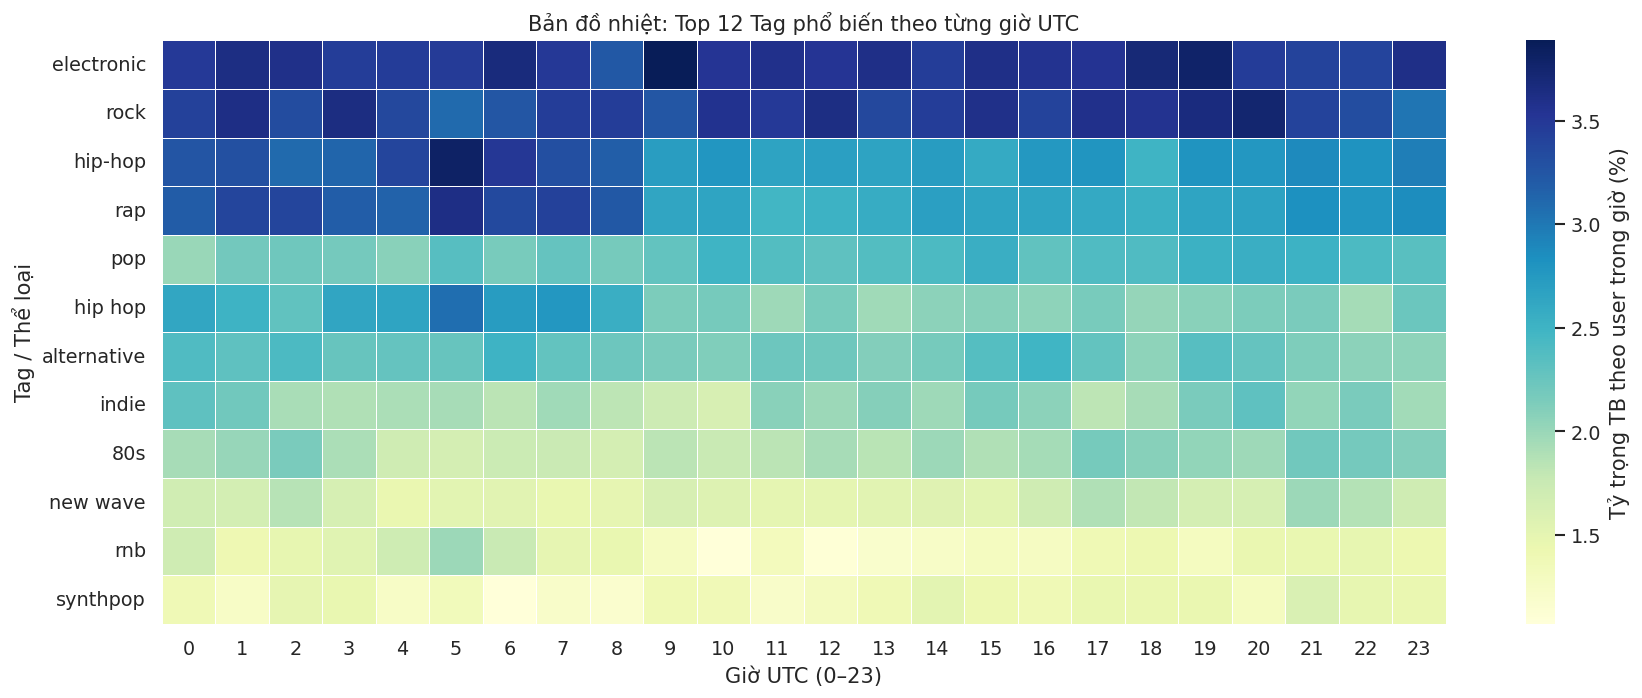

In [16]:
#biểu đồ giờ nào nghe tag gì
df_tags = hour_tags.toPandas()

# Chọn Top 12 tag có tổng tỷ trọng lớn nhất (tách riêng "(thiếu tag)" để không át thang màu)
top_tags = (
    df_tags[df_tags["tag"] != "(thiếu tag)"]
    .groupby("tag")["share_pct"].sum()
    .nlargest(12)
    .index.tolist()
)

pivot = (
    df_tags[df_tags["tag"].isin(top_tags)]
    .pivot(index="tag", columns="gio_utc", values="share_pct")
    .reindex(index=top_tags, columns=range(24), fill_value=0)
    .fillna(0)
)

plt.figure(figsize=(15, 6))
sns.heatmap(pivot, cmap="YlGnBu", annot=False, linewidths=0.3,
            cbar_kws={"label": "Tỷ trọng TB theo user trong giờ (%)"})
plt.title("Bản đồ nhiệt: Top 12 Tag phổ biến theo từng giờ UTC")
plt.xlabel("Giờ UTC (0–23)")
plt.ylabel("Tag / Thể loại")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_hour_tags_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

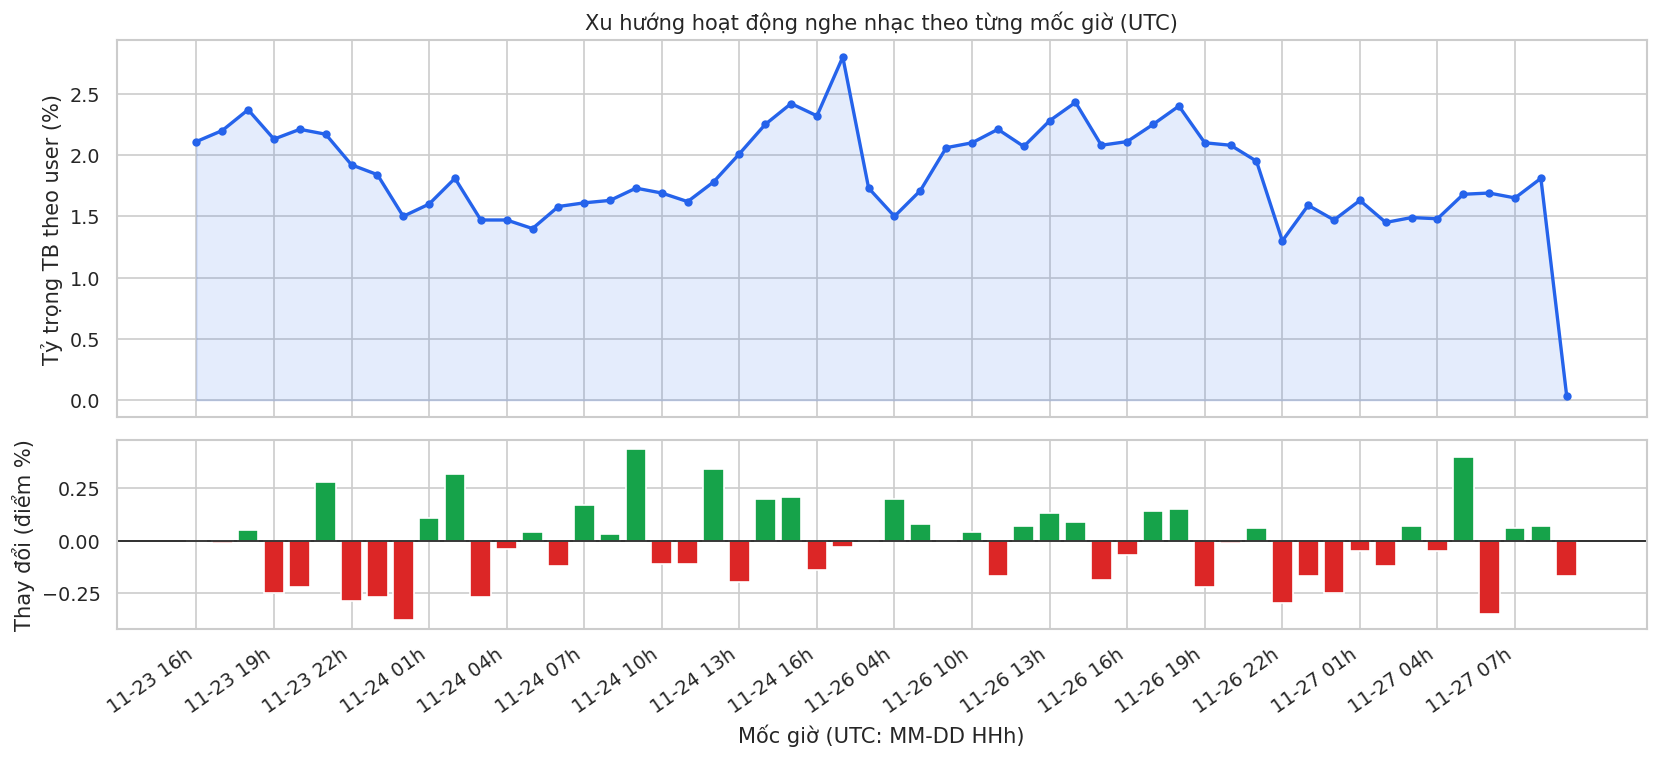

In [17]:
# 1) Tính bảng xu hướng theo từng mốc giờ UTC (tương tự weekly_trend nhưng theo giờ)
user_hours = (
    plays.withColumn("moc_gio_utc", F.date_trunc("hour", "ts_utc"))
    .groupBy("user", "moc_gio_utc").count()
    .join(coverage.select("user", "so_luot"), "user")
    .withColumn("user_share", F.col("count") / F.col("so_luot"))
)

hourly = user_hours.groupBy("moc_gio_utc").agg(
    F.sum("count").alias("so_luot"),
    F.count("*").alias("so_user_co_nghe"),
    F.round(100 * F.sum("user_share") / F.lit(n_users), 2).alias("share_pct"),
)

w_hour = Window.partitionBy("user").orderBy("moc_gio_utc")
paired_hour = (
    user_hours.withColumn("gio_truoc", F.lag("moc_gio_utc").over(w_hour))
    .withColumn("share_truoc", F.lag("user_share").over(w_hour))
    .where(F.unix_timestamp("moc_gio_utc") - F.unix_timestamp("gio_truoc") == 3600)
    .groupBy("moc_gio_utc").agg(
        F.count("*").alias("so_user_so_sanh"),
        F.round(100 * F.avg(F.col("user_share") - F.col("share_truoc")), 2).alias("thay_doi_diem_pct"),
    )
)

hourly_trend = hourly.join(paired_hour, "moc_gio_utc", "left").fillna(0, subset=["so_user_so_sanh"])

# 2) Vẽ biểu đồ 2 tầng: Tỷ trọng theo từng mốc giờ & Mức tăng/giảm so với giờ liền trước
df_htrend = hourly_trend.orderBy("moc_gio_utc").toPandas()
df_htrend["moc_str"] = pd.to_datetime(df_htrend["moc_gio_utc"]).dt.strftime("%m-%d %Hh")
x_pos = list(range(len(df_htrend)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

# Tầng trên: tỷ trọng nghe mỗi mốc giờ
ax1.plot(x_pos, df_htrend["share_pct"], marker="o", linewidth=2, markersize=4, color="#2563eb")
ax1.fill_between(x_pos, df_htrend["share_pct"], alpha=0.12, color="#2563eb")
if len(df_htrend) <= 24:
    for x, y, n_u in zip(x_pos, df_htrend["share_pct"], df_htrend["so_user_co_nghe"]):
        ax1.annotate(
            f"{y:.1f}%\n({int(n_u)}u)", (x, y),
            textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8
        )
ax1.set_title("Xu hướng hoạt động nghe nhạc theo từng mốc giờ (UTC)")
ax1.set_ylabel("Tỷ trọng TB theo user (%)")

# Tầng dưới: mức tăng/giảm so với giờ liền trước (xanh = tăng, đỏ = giảm)
delta = df_htrend["thay_doi_diem_pct"].astype(float)
colors = ["#16a34a" if pd.notna(v) and v >= 0 else "#dc2626" for v in delta]
ax2.bar(x_pos, delta.fillna(0), color=colors)
ax2.axhline(0, color="black", linewidth=0.9)
ax2.set_ylabel("Thay đổi (điểm %)")
ax2.set_xlabel("Mốc giờ (UTC: MM-DD HHh)")

# Tự giãn nhãn trục X nếu có nhiều mốc giờ để không bị chồng chữ
step = max(1, len(df_htrend) // 16)
ax2.set_xticks(x_pos[::step])
ax2.set_xticklabels(df_htrend["moc_str"].iloc[::step], rotation=35, ha="right")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_hourly_trend.png", dpi=200, bbox_inches="tight")
plt.show()